**Time-Resolved Methods Consistency Tests**

**0. What is tested**

1. `test_long_relaxation_consistency`: population kinetics, rotating-frame density evolution (RWA), and direct propagator density evolution give comparable spectra during slow population relaxation after the fast transverse transient.
2. `test_stationary_limit`: at two very late times, all three methods converge to the thermal `StationarySpectra` spectrum.

**1. Imports and settings**

In [7]:
import sys
from pathlib import Path

import numpy as np
import torch

import os
import sys
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..", "..", "..")))

from sample_generators import make_sample_case

SEED = 42
DTYPE = torch.float64
DEVICE = torch.device("cpu")

import matplotlib.pyplot as plt
from itertools import combinations
from mars import population, spectra_manager

FREQUENCY = 9.8e9
TEMPERATURE = 3.0
RATE = 1e3
DEPHASING = 1e7 
B1_FIELD = 1e-9
FIELDS = torch.linspace(0.27, 0.41, 240, dtype=DTYPE, device=DEVICE)



TIMES = torch.cat((
    torch.logspace(-5, -2.5, 35, dtype=DTYPE, device=DEVICE),
    torch.tensor([0.02, 0.04], dtype=DTYPE, device=DEVICE),
))
LONG_TIME_TOLERANCE = 0.05  # Relative to the largest transient signal
STATIONARY_TOLERANCE = 0.03


**2. Helper functions**

In [8]:
def normalized_signal(signal):
    """Normalize the CW reference and reject empty/invalid spectra."""
    assert torch.isfinite(signal).all(), "Nonfinite spectrum"
    scale = signal.abs().max()
    assert scale > 0, "Zero spectrum cannot establish consistency"
    return signal / scale


def simulate_case(sample, description):
    """Evaluate all three time-resolved methods and an independent CW reference."""
    F, _, _, _ = sample.get_hamiltonian_terms()
    dimension = F.shape[-1]
    thermal_rates = RATE * (torch.ones(dimension, dimension, dtype=DTYPE, device=DEVICE)
                            - torch.eye(dimension, dtype=DTYPE, device=DEVICE))
    initial = torch.zeros(dimension, dtype=DTYPE, device=DEVICE)
    initial[-1] = 1.0
    context = population.Context(
        basis="eigen", sample=sample, init_populations=initial,
        thermal_rates=thermal_rates,
        dephasing=torch.full((dimension,), DEPHASING, dtype=DTYPE, device=DEVICE),
        enforce_secularity=True, dtype=DTYPE, device=DEVICE,
    )
    settings = dict(
        freq=FREQUENCY, sample=sample, temperature=TEMPERATURE, harmonic=0,
        hamiltonian_mode="secular", dtype=DTYPE, device=DEVICE,
    )
    equilibrium_context = population.Context(
        basis="eigen", sample=sample, thermal_rates=thermal_rates,
        dephasing=torch.full((dimension,), DEPHASING, dtype=DTYPE, device=DEVICE),
        enforce_secularity=True, dtype=DTYPE, device=DEVICE,
    )
    spectra = {}
    for name, populator_class in (
        ("Kinetic", population.LevelBasedPopulator),
        ("RWA", population.RWADensityPopulator),
        ("Propagator", population.PropagatorDensityPopulator),
    ):
        extra = {} if name == "Kinetic" else dict(b1_field=B1_FIELD)
        if name == "Propagator":
            extra["n_steps"] = 256
        manager_class = (spectra_manager.TruncTimeSpectra if name == "Kinetic"
                         else spectra_manager.DensityTimeSpectra)

        def evaluate(evolution_context, times):
            populator = populator_class(
                context=evolution_context, init_temperature=TEMPERATURE, difference_out=False,
                dtype=DTYPE, device=DEVICE, **extra,
            )
            manager = manager_class(context=evolution_context, populator=populator, **settings)
            return manager(sample, FIELDS, times)

        signal = evaluate(context, TIMES)
        assert signal.shape == (len(TIMES), len(FIELDS)), (name, signal.shape)
        # Independent detector calibration: start from Boltzmann populations.
        # Wait 100 T2 for the microwave turn-on transient, without waiting for T1.
        equilibrium_signal = evaluate(equilibrium_context, TIMES[:2])
        assert torch.isfinite(signal).all() and torch.isfinite(equilibrium_signal).all(), name
        scale = equilibrium_signal.abs().max()
        assert scale > 0, f"{name}: zero equilibrium response"
        spectra[name] = signal / scale

    # No context: use the native Boltzmann stationary reference, independently of the initial state.
    stationary = spectra_manager.StationarySpectra(**settings)(sample, FIELDS)
    return dict(description=description, spectra=spectra, stationary=normalized_signal(stationary))


def plot_case(case):
    """Show late spectra and the relaxation kinetics at the strongest CW field."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    index = case["stationary"].abs().argmax().item()
    for name, signal in case["spectra"].items():
        axes[0].plot(FIELDS.cpu(), signal[-1].cpu(), label=name)
        axes[1].semilogx(TIMES.cpu(), signal[:, index].cpu(), label=name)
    axes[0].plot(FIELDS.cpu(), case["stationary"].cpu(), "k--", label="Stationary")
    axes[0].set(xlabel="Magnetic field (T)", ylabel="Normalized signal")
    axes[1].set(xlabel="Time (s)", ylabel="Normalized signal")
    for ax in axes:
        ax.legend()
    fig.suptitle(case["description"])
    plt.tight_layout()
    plt.show()


**3. Tests**

**3.1 Slow population relaxation**

Compare every pair over the full transient time/field grid (excluding the two equilibrium endpoints).

In [9]:
def test_long_relaxation_consistency(case):
    """Compare all three methods after the fast coherence transient."""
    for name, signal in case["spectra"].items():
        excursion = (signal[0] - signal[-1]).abs().max().item()
        assert excursion > 0.1, f"{name}: missing relaxation transient ({excursion:.2e})"
    for first, second in combinations(case["spectra"], 2):
        first_signal, second_signal = case["spectra"][first][:-2], case["spectra"][second][:-2]
        scale = torch.maximum(first_signal.abs().max(), second_signal.abs().max())
        error = ((first_signal - second_signal).abs().max() / scale).item()
        assert error < LONG_TIME_TOLERANCE, f"{first}/{second}: transient difference {error:.2e}"
    print(f"Long-relaxation consistency passed ({case['description']})")


**3.2 Stationary limit**

At both late times, compare each method with the independently computed thermal spectrum. Also require a late-time plateau.

In [10]:
def test_stationary_limit(case):
    """Check convergence of every method to the thermal stationary spectrum."""
    for name, signal in case["spectra"].items():
        # Keep the same scale used for the transient; do not renormalize the endpoint.
        error = (signal[-2:] - case["stationary"]).abs().max().item()
        plateau = (signal[-1] - signal[-2]).abs().max().item()
        assert error < STATIONARY_TOLERANCE, f"{name}: stationary difference {error:.2e}"
        assert plateau < 1e-3, f"{name}: not yet stationary ({plateau:.2e})"
    print(f"Stationary-limit consistency passed ({case['description']})")


**4. Test cases**

Reuse the four sample types: a spin-½ center, a spin-1 center with ZFS, their coupled system and their direct sum.

In [11]:
def iter_test_cases():
    rng = np.random.default_rng(SEED)
    samples = make_sample_case(
        rng, spins=(0.5, 1.0), partition=1, mesh=(5, 5), dtype=DTYPE, device=DEVICE,
    )
    names = ("sample_1", "sample_2", "sample_mul", "sample_direct_sum")
    for name, sample in zip(names, samples.samples):
        yield simulate_case(sample, name)


**5. Run the tests**

D:\ITC\РНФ_Курганский_2024\pythonProject\MarS\mars\spin_model.py:333: UserWarning: You are creating a block-diagonal (non-interacting) composite spin system via direct sum. This does NOT represent a true multi-particle quantum system (which would require a tensor-product space). Only use this if you are modeling effectively isolated subsystems (e.g., for polarized or time-resolved EPR). For physical spin clusters (diradicals, etc.), build a single SpinSystem with explicit couplings instead.
  concatenated_spin_system = concat_spin_systems(spin_systems)


Long-relaxation consistency passed (sample_1)
Stationary-limit consistency passed (sample_1)


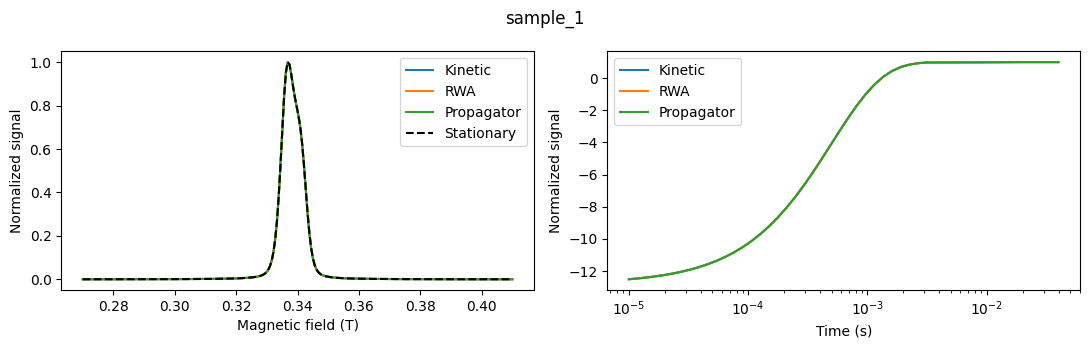

Long-relaxation consistency passed (sample_2)
Stationary-limit consistency passed (sample_2)


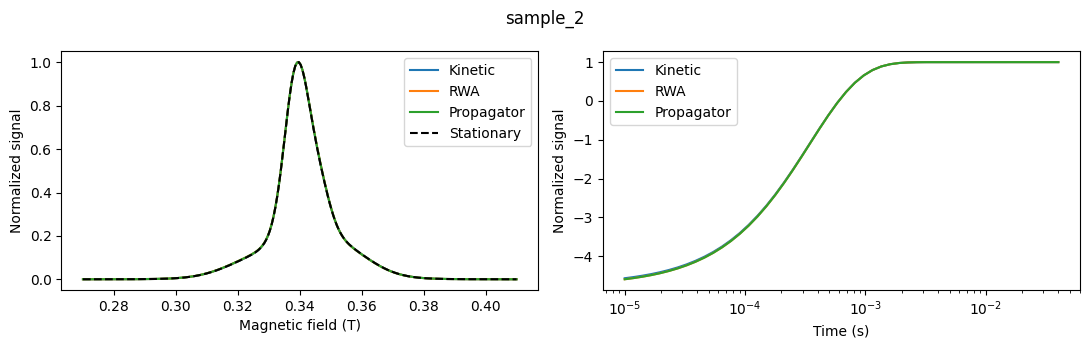

Long-relaxation consistency passed (sample_mul)
Stationary-limit consistency passed (sample_mul)


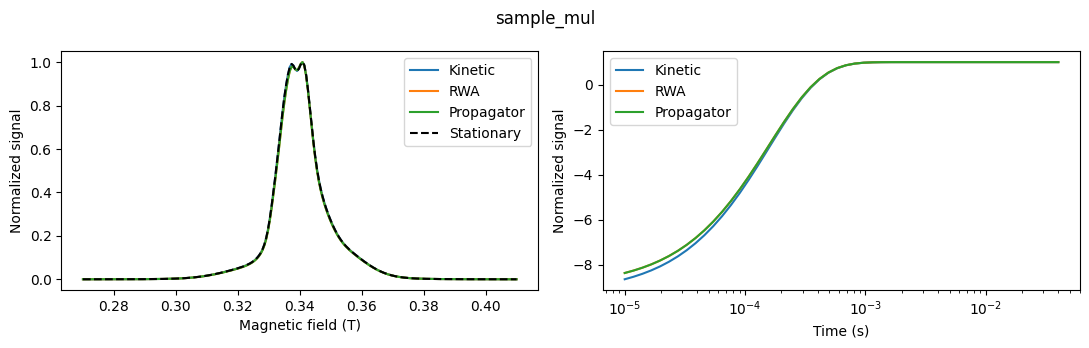

Long-relaxation consistency passed (sample_direct_sum)
Stationary-limit consistency passed (sample_direct_sum)


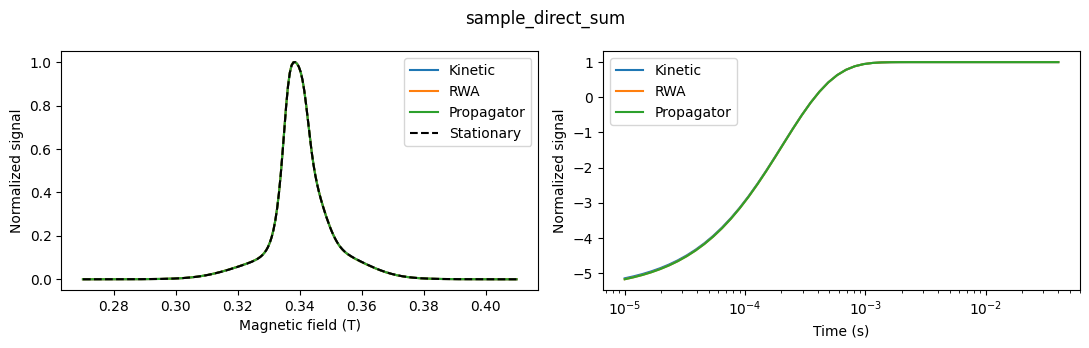


Both time-resolved consistency tests passed for all 4 samples.


In [12]:
def run_tests(show_plots=True):
    """Run the two tests for each sample fixture."""
    count = 0
    for case in iter_test_cases():
        test_long_relaxation_consistency(case)
        test_stationary_limit(case)
        if show_plots:
            plot_case(case)
        count += 1
    print(f"\nBoth time-resolved consistency tests passed for all {count} samples.")


run_tests()
